In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
from scipy.special import erf, erfc
from scipy.optimize import curve_fit
from scipy.stats import linregress

## Q1B

Now calculate and make a graph showing the trade-off between the inferred thickness of the upper mantle anisotropic layer and the estimated percent anisotropy of the mantle rocks, assuming a single anisotropic layer. How might one be able to constrain this trade off?

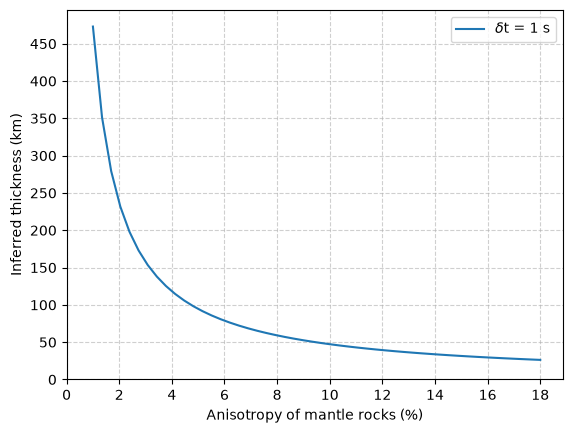

In [2]:
Vs = 4.73  # km/s; given by q2 (for peridotite)
dt = 1  # s; given by q1
anis = np.linspace(1, 18)
L = (dt * Vs) / (anis / 100)

plt.plot(anis, L, label="$\delta$t = 1 s")
# plt.plot(anis, ((dt-0.2) * Vs) / (anis / 100), label="$\delta$t = 0.8 s")
plt.xlabel("Anisotropy of mantle rocks (%)")
plt.ylabel("Inferred thickness (km)")
plt.xticks(np.arange(0, 20, 2))
plt.yticks(np.arange(0, 500, 50))
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.savefig("./attachments/fig1b.png", bbox_inches="tight")
plt.show()

## Q3

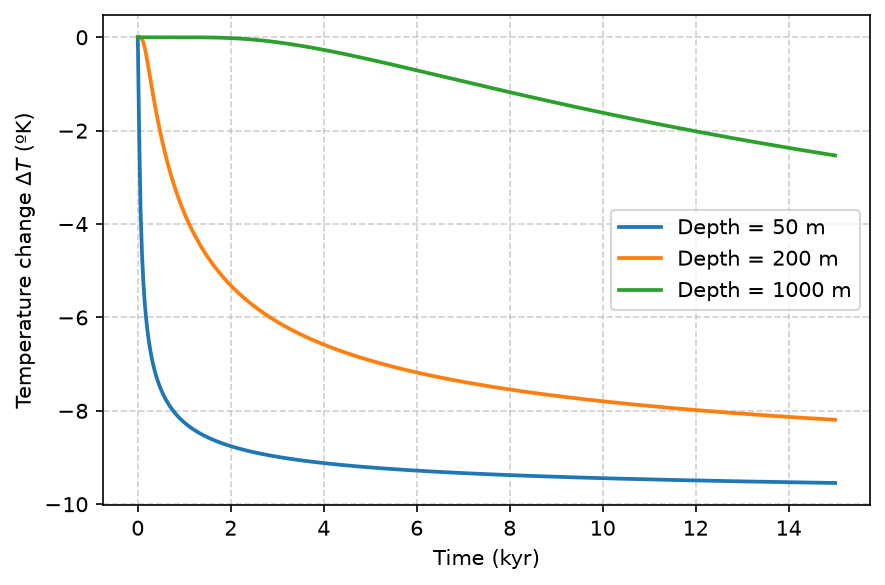

In [3]:
# Physical parameters
depths = np.array([50, 200, 1000])  # Convert km to meters
dT = -10  # K
time_years = np.linspace(1, 15000, 500)  # Time array in years
time_sec = time_years * 365.25 * 24 * 3600  # Convert years to seconds

conductivity = 1.5  # W/(m K)
heat_capacity = 700  # J/(kg K)
rho = 2650  # kg/m^3
thermal_diff = conductivity / (rho * heat_capacity)  # m^2/s

# Plotting
fig, ax = plt.subplots(figsize=(6, 4), dpi=150)

for z in depths:
    # Vectorized calculation using scipy's erf
    T = dT * erfc(z / (2 * np.sqrt(thermal_diff * time_sec)))
    ax.plot(time_years / 1000, T, label=f"Depth = {z} m", linewidth=1.8)

# Styling and formatting
ax.set_xlabel("Time (kyr)", fontsize=10)
ax.set_ylabel("Temperature change $\Delta T$ (ºK)", fontsize=10)
# ax.set_title("1D Transient Heat Diffusion into the Subsurface", fontsize=11, fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(frameon=True)

plt.savefig("./attachments/fig3.png", bbox_inches="tight")
plt.tight_layout()
plt.show()

## Q4A

Calculate and plot the temperature at 250~km depth for the half-space cooling model as a function of time.

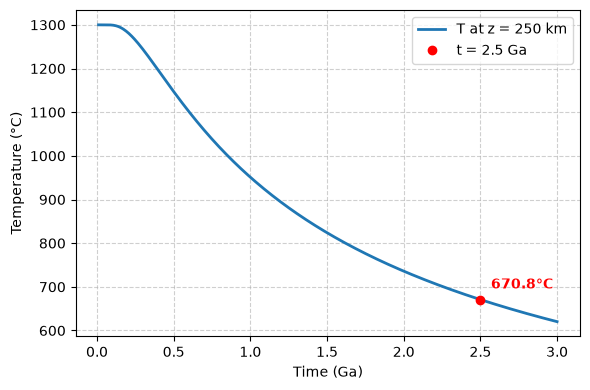

In [4]:
z = 250e3 # Depth in meters (250 km)
Ts = 0.0 # Surface temp (°C)
Tm = 1300.0 # Mantle temp (°C)

conductivity = 1.5  # W/(m K)
heat_capacity = 700  # J/(kg K)
rho = 2650  # kg/m^3
kappa = conductivity / (rho * heat_capacity)  # thermal diffusivity (m^2/s)

t_yr = np.linspace(0.01, 3.0, 500) * 1e9
t_sec = t_yr * 365.25 * 24 * 3600

# half space cooling
T = Ts + (Tm - Ts) * erf(z / (2 * np.sqrt(kappa * t_sec)))

t250 = 1300 * math.erf((250 * 10**3) / (2 * math.sqrt((1.5 / (2650 * 700)) * (2.5 * 10**9 * 365.25 * 24 * 3600))))

plt.figure(figsize=(6, 4))
plt.plot(t_yr / 1e9, T, '-', lw=2, label="T at z = 250 km")
# plt.axvline(2.5, color='r', linestyle='--', label="Craton age (2.5 Ga)")
plt.plot(2.5, t250, color="red", marker="o", label="t = 2.5 Ga", linestyle="")
plt.annotate(
    f" {t250:.1f}°C",  # Text string to display
    (2.5, t250),  # (x, y) point to annotate
    textcoords="offset points",  # Position text relative to point in pixels
    xytext=(4,8),  # Shift text 8px right, 4px down
    fontsize=10,
    fontweight="bold",
    color="red",
)
plt.xlabel("Time (Ga)")
plt.ylabel("Temperature (°C)")
# plt.title("Half-Space Cooling Temperature at 250 km Depth")
plt.grid(True, ls='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("./attachments/fig4a.png", bbox_inches="tight")
plt.show()

In [5]:
print(f"{t250:.2f}")

670.80


## Q5

### Part 1

/var/folders/kx/_4y_qnz528xckbxwtfngwfh80000gn/T/ipykernel_36669/3520508135.py:18: RuntimeWarning: invalid value encountered in sqrt
  return 0.5 * (CL_val - CR_val) * erfc((x_arr - x0) / (2 * np.sqrt(D * t_sec))) + CR_val
/var/folders/kx/_4y_qnz528xckbxwtfngwfh80000gn/T/ipykernel_36669/3520508135.py:18: RuntimeWarning: invalid value encountered in sqrt
  return 0.5 * (CL_val - CR_val) * erfc((x_arr - x0) / (2 * np.sqrt(D * t_sec))) + CR_val
/var/folders/kx/_4y_qnz528xckbxwtfngwfh80000gn/T/ipykernel_36669/3520508135.py:18: RuntimeWarning: invalid value encountered in sqrt
  return 0.5 * (CL_val - CR_val) * erfc((x_arr - x0) / (2 * np.sqrt(D * t_sec))) + CR_val


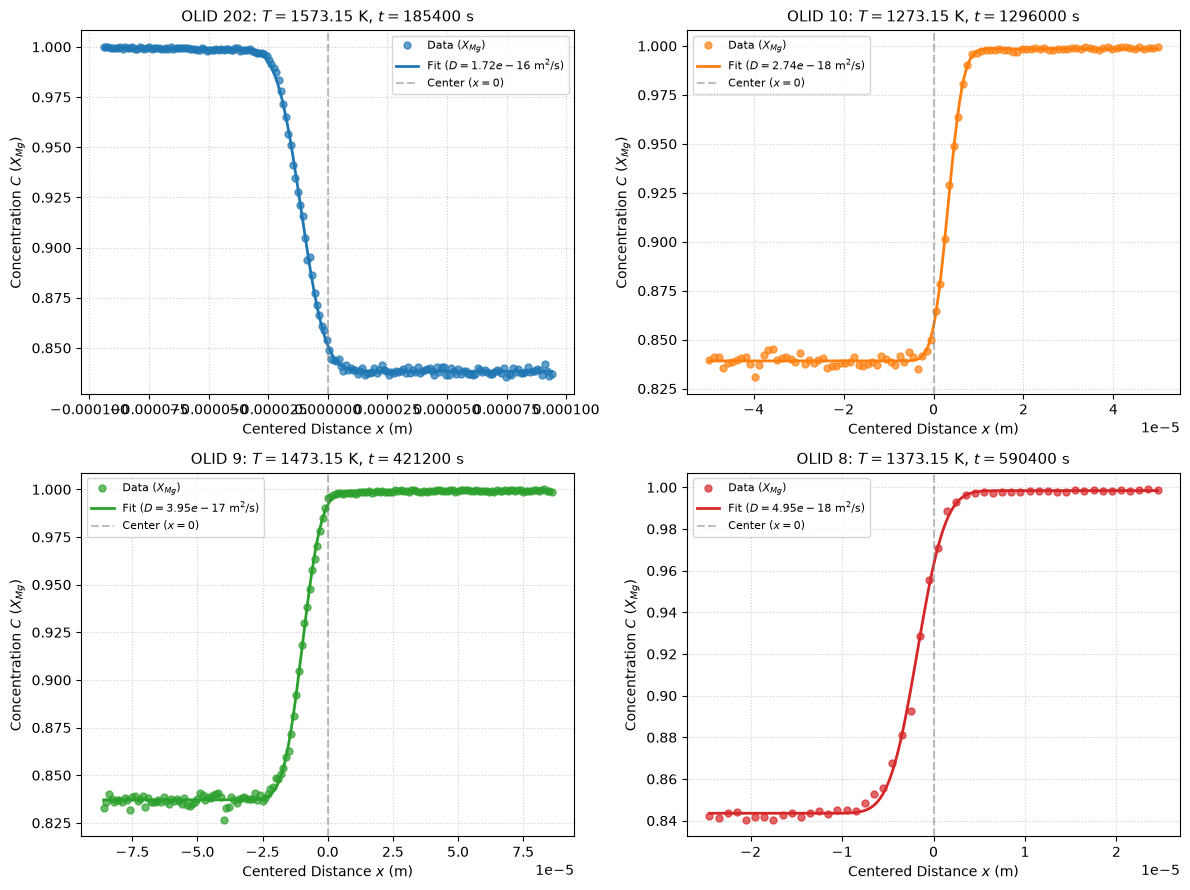

In [11]:
def C_2_K(temp_C):
    return temp_C + 273.15

def hr_2_sec(time_hrs):
    return time_hrs * 3600

um_to_m_factor = 1e-6

experiments = {
    "OLID 202": [1300, 51.5],
    "OLID 10": [1000, 360],  # Update temp/time per your excel file
    "OLID 9": [1200, 117],
    "OLID 8": [1100, 164],
}

# Shared diffusion model function
def diffusion_model(x_arr, D, x0, CL_val, CR_val, t_sec):
    return 0.5 * (CL_val - CR_val) * erfc((x_arr - x0) / (2 * np.sqrt(D * t_sec))) + CR_val

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=False)
axes = axes.flatten()

colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

results = []
for idx, (sheet, (temp_C, time_hrs)) in enumerate(experiments.items()):
    ax = axes[idx]
    temp_K = C_2_K(temp_C)
    time_s = hr_2_sec(time_hrs)

    df = pd.read_excel("./problem_set_2_2026.xlsx", sheet_name=sheet, skiprows=[0, 1, 2], usecols=[1, 2, 3], header=0)

    # dist from um to m; center on x axis
    dist_m = df["Dist"].values * um_to_m_factor
    x_center_m = np.mean(dist_m)
    x = dist_m - x_center_m

    # conc in Fo content (XMg) ranging 0-1
    C_data = df["XMg"].values
    CL = C_data[0]
    CR = C_data[-1]

    # fit using scipy curve_fit (LSR)
    fit_func = lambda x_arr, D, x0, cL, cR: diffusion_model(x_arr, D, x0, cL, cR, t_sec=time_s)
    p0 = [1e-16, 0.0, CL, CR]

    popt, _ = curve_fit(fit_func, x, C_data, p0=p0)
    D_fit, x0_fit, CL_fit, CR_fit = popt
    experiments[sheet].append(D_fit)

    results.append(
        {
            "Experiment": sheet,
            "Temp_C": temp_C,
            "Temp_K": temp_K,
            "1/T_K": 1.0 / temp_K,
            "Time_hrs": time_hrs,
            "Time_s": time_s,
            "D_m2_s": D_fit,
            "ln_D": np.log(D_fit),
        }
    )

    # experimental data
    color = colors[idx % len(colors)]
    ax.plot(x, C_data, "o", color=color, alpha=0.7, markersize=5, label="Data ($X_{Mg}$)")

    # plot fit line
    x_fit = np.linspace(x.min(), x.max(), 200)
    y_fit = fit_func(x_fit, *popt)
    ax.plot(x_fit, y_fit, "-", color=color, linewidth=2, label=f"Fit ($D = {D_fit:.2e}\\ \\mathrm{{m^2/s}}$)")

    ax.axvline(0, color="gray", linestyle="--", alpha=0.5, label="Center ($x=0$)")
    ax.set_xlabel("Centered Distance $x$ (m)", fontsize=10)
    ax.set_ylabel("Concentration $C$ ($X_{Mg}$)", fontsize=10)
    ax.set_title(f"{sheet}: $T = {temp_K:.2f}\\ \\mathrm{{K}}$, $t = {time_s:.0f}\\ \\mathrm{{s}}$", fontsize=11)
    ax.legend(frameon=True, loc="best", fontsize=8)
    ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig("attachments/fig51a.png")
plt.show()

In [ ]:
experiments

{'OLID 202': [1300, 51.5, np.float64(1.717451226620896e-16)],
 'OLID 10': [1000, 360, np.float64(2.736524489733305e-18)],
 'OLID 9': [1200, 117, np.float64(3.947450927561386e-17)],
 'OLID 8': [1100, 164, np.float64(4.948676584920008e-18)]}

In [ ]:
for e in experiments.items():
    print(f"D_Mg for {e[0]} = {e[1][2]:.2e}")

D_Mg for OLID 202 = 1.72e-16
D_Mg for OLID 10 = 2.74e-18
D_Mg for OLID 9 = 3.95e-17
D_Mg for OLID 8 = 4.95e-18


Pre-exponential factor (D0): 1.119e-08 m^2/s
Activation energy (Q): 238.50 kJ/mol (238498.09 J/mol)
R-squared: 0.9414
Slope (-Q/R): -28684.7271
Intercept (ln D0): -18.3082



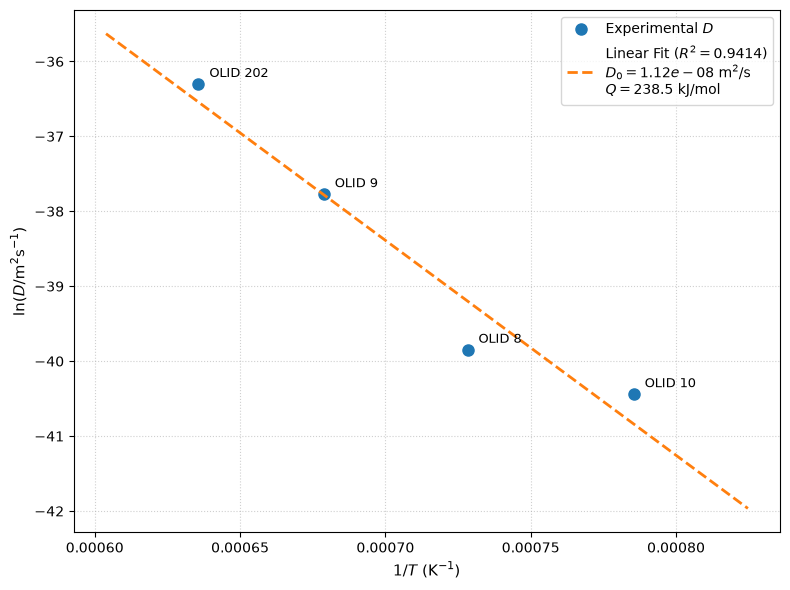

In [ ]:
R = 8.314462618  # J / (mol * K)

df_results = pd.DataFrame(results)

x_arrh = df_results["1/T_K"].values
y_arrh = df_results["ln_D"].values

slope, intercept, r_value, p_value, std_err = linregress(x_arrh, y_arrh)

Q_J_mol = -slope * R
Q_kJ_mol = Q_J_mol / 1000.0
D0 = np.exp(intercept)
R_squared = r_value**2

print(f"Pre-exponential factor (D0): {D0:.3e} m^2/s")
print(f"Activation energy (Q): {Q_kJ_mol:.2f} kJ/mol ({Q_J_mol:.2f} J/mol)")
print(f"R-squared: {R_squared:.4f}")
print(f"Slope (-Q/R): {slope:.4f}")
print(f"Intercept (ln D0): {intercept:.4f}\n")

plt.figure(figsize=(8, 6))

plt.plot(
    df_results["1/T_K"],
    df_results["ln_D"],
    "o",
    markersize=8,
    label="Experimental $D$",
)

x_line = np.linspace(df_results["1/T_K"].min() * 0.95, df_results["1/T_K"].max() * 1.05, 100)
y_line = slope * x_line + intercept

plt.plot(
    x_line,
    y_line,
    "--",
    linewidth=2,
    label=(
        f"Linear Fit ($R^2 = {R_squared:.4f}$)\n"
        f"$D_0 = {D0:.2e}\\ \\mathrm{{m^2/s}}$\n"
        f"$Q = {Q_kJ_mol:.1f}\\ \\mathrm{{kJ/mol}}$"
    ),
)

# Annotate points with experiment names
for _, row in df_results.iterrows():
    plt.annotate(
        f" {row['Experiment']}",
        (row["1/T_K"], row["ln_D"]),
        textcoords="offset points",
        xytext=(5, 5),
        ha="left",
        fontsize=9,
    )

plt.xlabel("$1/T$ (K$^{-1}$)", fontsize=11)
plt.ylabel("$\ln(D / \\mathrm{m}^2\\mathrm{s}^{-1})$", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(frameon=True, loc="best", fontsize=10)
plt.tight_layout()
plt.savefig("attachments/fig51b.png")
plt.show()

## Q5b

In [41]:
T = 1150 + 273.15

etna = pd.read_excel(
    "./problem_set_2_2026.xlsx", usecols=[0, 1], skiprows=5, sheet_name="Natural oliv"
)

etna.head()

,Distance,Fo
0,0.000000,77.391633
1,8.265306,79.236521
2,16.530612,80.112988
3,24.795918,80.757768
4,33.061224,80.916755


In [40]:
D_Etna = D0 * np.exp(-Q_J_mol / (R * T))

print(f"Mt. Etna diff @ 1150 C: {D_Etna:.2e} m^2/s")

Mt. Etna diff @ 1150 C: 1.97e-17 m^2/s


```
def diffusion_model(x_arr, D, x0, CL_val, CR_val, t_sec):
    return 0.5 * (CL_val - CR_val) * erfc((x_arr - x0) / (2 * np.sqrt(D * t_sec))) + CR_val
```

Timescale t: 1.27e+07 seconds
Timescale t: 3516.1 hours
Timescale t: 146.5 days


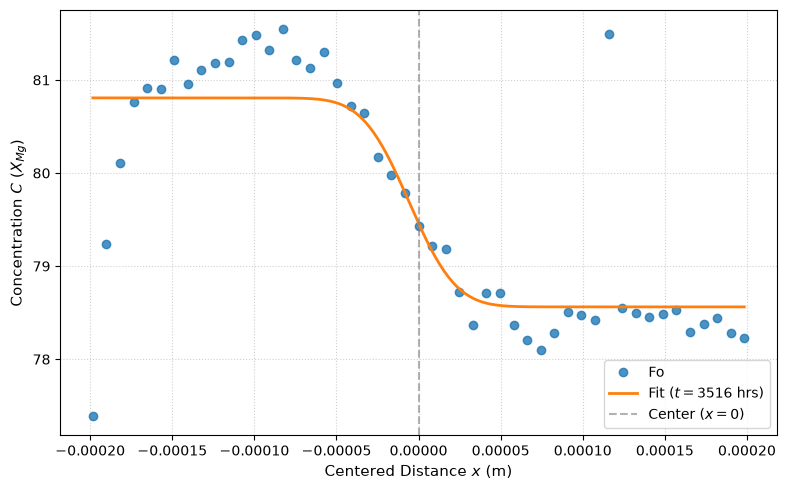

In [53]:
dist_m = etna["Distance"].values * um_to_m_factor
x_center = np.mean(dist_m)
x_etna = dist_m - x_center

C_etna = etna["Fo"].values
CL_etna = C_etna[0]
CR_etna = C_etna[-1]

def etna_diffusion_model(x_arr, t_sec, x0=0.0, CL=CL_etna, CR=CR_etna):
    return 0.5 * (CL - CR) * erfc((x_arr - x0) / (2 * np.sqrt(D_Etna * t_sec))) + CR

# Initial guess: t ~ 30 days in seconds (~2.5e6 s)
p0 = [200 * 24 * 3600, 0.0, CL_etna, CR_etna]

popt_etna, _ = curve_fit(etna_diffusion_model, x_etna, C_etna, p0=p0)
t_fit_sec, x0_fit, CL_fit, CR_fit = popt_etna

# Convert time to human-readable units
t_fit_hrs = t_fit_sec / 3600.0
t_fit_days = t_fit_sec / (24 * 3600.0)

print(f"Timescale t: {t_fit_sec:.2e} seconds")
print(f"Timescale t: {t_fit_hrs:.1f} hours")
print(f"Timescale t: {t_fit_days:.1f} days")

# --- 4. Plotting ---
plt.figure(figsize=(8, 5))

plt.plot(x_etna, C_etna, "o", alpha=0.8, label="Fo")

x_fit = np.linspace(x_etna.min(), x_etna.max(), 300)
y_fit = etna_diffusion_model(x_fit, *popt_etna)

plt.plot(
    x_fit,
    y_fit,
    "-",
    linewidth=2,
    label=f"Fit ($t = {t_fit_hrs:.0f}$ hrs)"
)

plt.axvline(0, color="gray", linestyle="--", alpha=0.6, label="Center ($x=0$)")
plt.xlabel("Centered Distance $x$ (m)", fontsize=11)
plt.ylabel("Concentration $C$ ($X_{Mg}$)", fontsize=11)
# plt.title(f"Mount Etna Olivine Fe-Mg Diffusion Profile\n$T = 1150^\\circ\\mathrm{{C}}$ ({T:.1f} K)", fontsize=12)
plt.legend(frameon=True, loc="best", fontsize=10)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig("attachments/fig52.png")
plt.show()